# Guide: first simulation

Runs, unchanged, the code shown on the page *Getting started → First simulation*: a half-wave strip dipole at 300 MHz, from the gmsh geometry to the input impedance and the radiation pattern.

Documentation plumbing, kept apart from the page code:
- the notebook works in a temporary folder, so the `data/` tree the solver writes does not land in the repository;
- the solver's plotting functions call `fig.show()`; `Figure.show` is wrapped so that each Plotly figure is also kept, then exported as a static image for the page (the figures themselves are the solver's).

The cells marked **PAGE** are copied verbatim into the page.

In [1]:
# Documentation plumbing (not on the page)
%matplotlib inline
import datetime, io, json, os, tempfile, contextlib
from pathlib import Path

import matplotlib.pyplot as plt
import plotly.graph_objects as go

DOC_DIR = Path.cwd()
OUT_DIR = (DOC_DIR / "../source/figures/generated").resolve()
WORK = Path(tempfile.mkdtemp(prefix="mom_docs_first_sim_"))
os.chdir(WORK)
print("working directory:", WORK)

captured = []
_show = go.Figure.show
def _capture(self, *args, **kwargs):
    captured.append(self)
    return _show(self, *args, **kwargs)
go.Figure.show = _capture

mpl_figures = []
_plt_show = plt.show
def _plt_capture(*args, **kwargs):
    mpl_figures.append(plt.gcf())
    return _plt_show(*args, **kwargs)
plt.show = _plt_capture

working directory: C:\Users\foyendou\AppData\Local\Temp\mom_docs_first_sim_rvbxtmgm


In [2]:
# PAGE: imports and file paths
import gmsh
import numpy as np

from solver.utils.file_path import setup_save_file_paths
from solver.utils.gmsh_function import (mesh_and_gap_parameters, setup_performance_config,
                                        generate_and_save_mesh, check_simulation_stability)
from solver.src.radiation_algorithm.radiation_algorithm import radiation_algorithm
from solver.efield.efield2 import radiation_intensity_distribution_over_sphere_surface
from solver.efield.efield3 import antenna_directivity_pattern

path = setup_save_file_paths("strip_dipole")

Directory created: data/gmsh_files/
Directory created: data/antennas_mesh/
Directory created: data/antennas_mesh1/
Directory created: data/antennas_mesh2/
Directory created: data/antennas_impedance/
Directory created: data/antennas_current/
Directory created: data/antennas_gain_power/
Directory created: data/antennas_sweep/


In [3]:
# PAGE: geometry and mesh
frequency = 300e6                 # Hz, wavelength 1 m
length, width = 0.47, 0.01        # m: a strip along y, centred at the origin

# Element size and gap width from the frequency: gap = 0.05 wavelength,
# elements of wavelength/60, so that 3 elements fit in the gap.
mesh_size, gap_width, wavelength = mesh_and_gap_parameters(frequency, resolution=60, gap_fraction=0.05)

gmsh.initialize()
gmsh.model.add(path.name)
setup_performance_config(n_threads=1)          # one thread: the same mesh every run
strip = gmsh.model.occ.addRectangle(-width / 2, -length / 2, 0, width, length)
gap = gmsh.model.occ.addRectangle(-width / 2, -gap_width / 2, 0, width, gap_width)
gmsh.model.occ.fragment([(2, strip)], [(2, gap)])   # the gap edges become mesh lines
gmsh.model.occ.synchronize()
generate_and_save_mesh(path, mesh_size)
gmsh.finalize()

λ = 1.0000 m  |  mesh_size = λ/60 = 0.0167 m  |  gap = 0.05λ = 0.0500 m  |  N_edges_in_gap ≈ 3.0
[PERFORMANCE] Gmsh configured to utilize 1 threads.
Geometry file saved in data/gmsh_files/strip_dipole.brep successfully
--- Starting Mesh Optimization (Dim: 2) ---
--- Optimization Complete ---
Mesh file saved in data/gmsh_files/strip_dipole.msh successfully


In [4]:
# PAGE: solve
feed_point = np.array([0.0, 0.0, 0.0])        # centre of the strip

(Z, V, I, surface_current_density,
 gap_currents, gap_voltages, impedances, feed_powers) = radiation_algorithm(
    path, frequency, feed_point,
    voltage_amplitude=1,                       # 1 V peak across the gap
    excitation_unit_vector="y",                # the gap field points along the strip
    gap_width=gap_width,
)

print(f"Input impedance: {impedances[0]:.2f} Ohm")
print(f"Input power:     {feed_powers[0] * 1e3:.3f} mW")
check_simulation_stability(impedances, frequency, mesh_size, gap_width)

Number of points: 89
Number of triangles: 116
Number of edges: 144
[calculate_z_matrice] Using GPU (NVIDIA T600 Laptop GPU, CuPy 14.1.1) for the impedance matrix assembly (144x144 edges).


Total input power P_in = 0.5*Re(V·I*) = 6.852393e-03 W
Port 0: P_in = 6.8524e-03 W  |  Q_in = 3.8490e-04 VAR  |  Z_in = 72.7377+4.0857j Ohm


Input impedance: 72.74+4.09j Ohm
Input power:     6.852 mW

[Stability Check]
  Port 0: Z_in = 72.74+4.09j Ω  — ✓ OK
  Gap check: gap/mesh = 3.0 ≥ 3 — ✓ OK
  Mesh check: λ/60 — ✓ in recommended range [λ/10, λ/100]
  Overall: ✓ PASS


True

Hollow sphere .mat file not found. Checking for .msh file...
Hollow sphere .msh file not found. Creating it...


Hollow sphere loaded: 5150 points, 10296 triangles.



[Antenna Results]
  Total Radiated Power : 0.0068561612963706445 W
  Gain : 1.6341 (2.13 dBi)

[Power Budget]
  P_in  (0.5*Re(V·I*)) = 6.852393e-03 W
  P_rad (sphere integ.) = 6.856161e-03 W
  Raw efficiency       = 100.0550 %
  Port 0: Z_in = 72.7377+4.0857j Ω  |  R_in = 72.7377 Ω
  Total Efficiency     = 100.00 %
Data saved successfully to data/antennas_gain_power/strip_dipole_gain_power.mat


Data loaded from data/antennas_gain_power/strip_dipole_gain_power.mat


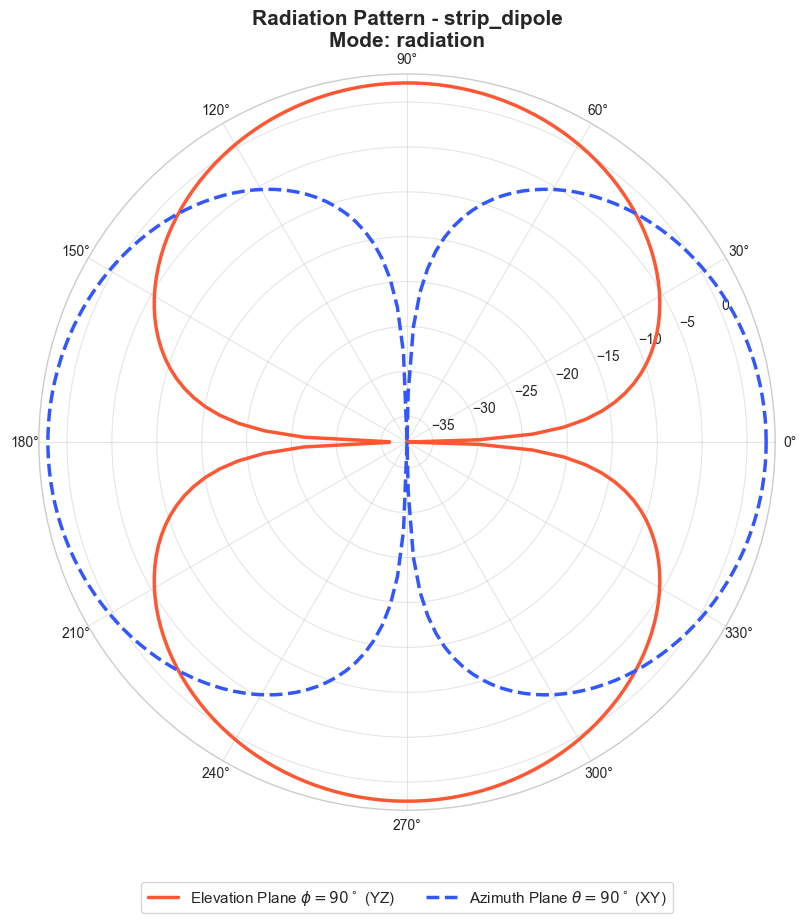

In [5]:
# PAGE: radiation pattern
radiation_intensity_distribution_over_sphere_surface(path)   # 3D pattern, "Gain" (a directivity), efficiency
antenna_directivity_pattern(path)                            # two polar cuts

In [6]:
# PAGE: files written
for folder in sorted(Path("data").iterdir()):
    print(folder.as_posix() + "/", [f.name for f in sorted(folder.iterdir())])

data/antennas_current/ ['strip_dipole_current.mat']
data/antennas_gain_power/ ['strip_dipole_gain_power.mat']
data/antennas_impedance/ ['strip_dipole_impedance.mat']
data/antennas_mesh/ ['hollow_sphere.mat', 'strip_dipole.mat']
data/antennas_mesh1/ ['strip_dipole_mesh1.mat']
data/antennas_mesh2/ ['strip_dipole_mesh2.mat']
data/antennas_sweep/ []
data/gmsh_files/ ['hollow_sphere.msh', 'strip_dipole.brep', 'strip_dipole.msh']


In [7]:
# PAGE (data-and-files): reload the results without recomputing
from solver.rwg.rwg2 import DataManager_rwg2
from solver.rwg.rwg3 import DataManager_rwg3
from solver.rwg.rwg4 import DataManager_rwg4

points, triangles, edges, vecteurs_rho = DataManager_rwg2.load_data(path.mat_mesh2)
frequency, omega, mu, epsilon, light_speed_c, eta, Z = DataManager_rwg3.load_data(path.mat_impedance)
(frequency, omega, mu, epsilon, light_speed_c, eta,
 V, I, gap_currents, gap_voltages, impedances, feed_powers) = DataManager_rwg4.load_data(path.mat_current, radiation=True)

print(edges.total_number_of_edges, "edges;", Z.shape, "matrix;", "Z_in =", np.round(impedances, 2), "Ohm")

144 edges; (144, 144) matrix; Z_in = (72.74+4.09j) Ohm


In [8]:
# Documentation plumbing: static images and interactive HTML of the solver's figures, and provenance
import copy
print(len(captured), "Plotly figures,", len(mpl_figures), "matplotlib figures captured")
names = ["first_simulation_current", "first_simulation_pattern"]
exported = {}
for fig, name in zip(captured, names):
    # Interactive version: a <div> + script fragment; the page loads plotly.js once and
    # _static/js/live-figures.js moves the wrapper into the {figure} that follows it.
    live = copy.deepcopy(fig)
    live.update_layout(width=None, height=560, autosize=True, margin=dict(l=0, r=0, t=40, b=0),
                       paper_bgcolor="white")
    fragment = live.to_html(full_html=False, include_plotlyjs=False, div_id=name,
                            config={"responsive": True, "displaylogo": False})
    (OUT_DIR / f"{name}.html").write_text(
        f'<div class="mom-live-figure pst-js-only">\n{fragment}\n</div>\n', encoding="utf-8")
    # Static version: shown without JavaScript, and in print
    fig.update_layout(width=900, height=650, margin=dict(l=0, r=0, t=40, b=0), paper_bgcolor="white")
    fig.write_image(str(OUT_DIR / f"{name}.png"), scale=2)
    exported[name] = [f"{name}.png", f"{name}.html"]
if mpl_figures:
    target = OUT_DIR / "first_simulation_polar.png"
    mpl_figures[-1].savefig(target, dpi=150, bbox_inches="tight", facecolor="white")
    exported["first_simulation_polar"] = [target.name]
for name, files in exported.items():
    print(name, [(f, round((OUT_DIR / f).stat().st_size / 1024)) for f in files], "kB")

def git_commit(repo=DOC_DIR / "../.."):
    git_dir = repo / ".git"
    head = (git_dir / "HEAD").read_text().strip()
    if not head.startswith("ref: "):
        return head[:7]
    ref_file = git_dir / head[5:]
    if ref_file.exists():
        return ref_file.read_text().strip()[:7]
    for line in (git_dir / "packed-refs").read_text().splitlines():
        if line.endswith(" " + head[5:]):
            return line.split()[0][:7]
    return "unknown"

import plotly
provenance = {
    "notebook": "documentation/figure_notebooks/guide_first_simulation.ipynb",
    "solver_commit": git_commit(),
    "generated": datetime.date.today().isoformat(),
    "plotly_version": plotly.__version__,
    "figures": exported,
    "mesh_size_m": mesh_size, "gap_width_m": gap_width,
    "n_edges": int(Z.shape[0]),
    "z_in_ohm": [float(np.atleast_1d(impedances)[0].real), float(np.atleast_1d(impedances)[0].imag)],
    "p_in_w": float(np.atleast_1d(feed_powers)[0]),
}
(OUT_DIR / "first_simulation.json").write_text(json.dumps(provenance, indent=2), encoding="utf-8")
print(json.dumps(provenance, indent=2))
os.chdir(DOC_DIR)

2 Plotly figures, 1 matplotlib figures captured


first_simulation_current [('first_simulation_current.png', 130), ('first_simulation_current.html', 38)] kB
first_simulation_pattern [('first_simulation_pattern.png', 218), ('first_simulation_pattern.html', 483)] kB
first_simulation_polar [('first_simulation_polar.png', 241)] kB
{
  "notebook": "documentation/figure_notebooks/guide_first_simulation.ipynb",
  "solver_commit": "4282bf8",
  "generated": "2026-11-11",
  "plotly_version": "6.2.0",
  "figures": {
    "first_simulation_current": [
      "first_simulation_current.png",
      "first_simulation_current.html"
    ],
    "first_simulation_pattern": [
      "first_simulation_pattern.png",
      "first_simulation_pattern.html"
    ],
    "first_simulation_polar": [
      "first_simulation_polar.png"
    ]
  },
  "mesh_size_m": 0.016666666666666666,
  "gap_width_m": 0.05,
  "n_edges": 144,
  "z_in_ohm": [
    72.73771385788041,
    4.08573838081387
  ],
  "p_in_w": 0.006852392711906691
}
